# Entrega final — Asistente turístico de Tenerife

> **Autor/a:** Luis  
> **Fecha:** 20/10/2026 

Este notebook se ha generado una plantilla inicialmente con IA. Las implementaciones, ejecuciones, decisiones y explicaciones deben ser completadas por el alumno.

## Cómo usar esta plantilla

1. Ejecuta las secciones en orden.
2. Sustituye cada marcador `TODO` por tu código o explicación.
3. Mantén visibles los resultados que demuestran los requisitos.
4. No afirmes que una mejora funciona sin mostrar una comparación.
5. Distingue código ejecutado, propuesta y limitación.
6. Antes de entregar, reinicia el kernel y ejecuta todo desde cero.

## 0. Requisitos del proyecto y decisiones iniciales

Completa esta tabla antes de programar.

| Decisión | Elección | Justificación |
| --- | --- | --- |
| Proveedor | TODO | TODO |
| Modelo generativo | TODO | TODO |
| Modelo de embeddings | TODO | TODO |
| Temperatura | TODO | TODO |
| Top-p | TODO | TODO |
| Máximo de tokens de salida | TODO | TODO |
| Vector store | TODO | TODO |
| Estrategia inicial de memoria | TODO | TODO |
| Tiempo real o simulado | TODO | TODO |

### 0.1 Imports, rutas y versiones

Se incluye una revisión de el PDF que vamos a usar como RAG existe, que los directorios de los proyectos existen y además, las versiones de las diferentes herramientas que se van a utilizar

In [9]:
# TODO: comprobar que el PDF existe
import os
import sys
from pathlib import Path

import langchain
import openai
import pypdf
from dotenv import load_dotenv


def find_project_dir() -> Path:
    """Localiza la raíz del proyecto de la Entrega Final."""
    current_dir = Path.cwd().resolve()

    # Caso 1: Jupyter se ha iniciado desde la raíz del proyecto.
    if (current_dir / "data" / "TENERIFE.pdf").exists():
        return current_dir

    # Caso 2: Jupyter se ha iniciado desde la carpeta notebooks.
    if (current_dir.parent / "data" / "TENERIFE.pdf").exists():
        return current_dir.parent

    raise FileNotFoundError(
        "No se ha encontrado data/TENERIFE.pdf desde el directorio actual "
        "ni desde su directorio padre."
    )


PROJECT_DIR = find_project_dir()
# Rutas utilizadas durante la práctica.
ENV_PATH = PROJECT_DIR / ".env"
PDF_PATH = PROJECT_DIR / "data" / "TENERIFE.pdf"
LOGS_DIR = PROJECT_DIR / "logs"

# Comprobación de rutas.
print("Directorio del proyecto:", PROJECT_DIR)
print("Archivo .env encontrado:", ENV_PATH.exists())
print("PDF encontrado:", PDF_PATH.exists())
print("Directorio de logs:", LOGS_DIR)

# Versiones relevantes para la reproducibilidad.
print("\nVersiones:")
print("Python:", sys.version.split()[0])
print("OpenAI:", openai.__version__)
print("PyPDF:", pypdf.__version__)
print("LangChain:", langchain.__version__)

Directorio del proyecto: C:\Users\ltorres\Desktop\IA\IA_Luis\Entrega Final\Entrega Final
Archivo .env encontrado: True
PDF encontrado: True
Directorio de logs: C:\Users\ltorres\Desktop\IA\IA_Luis\Entrega Final\Entrega Final\logs

Versiones:
Python: 3.11.9
OpenAI: 2.38.0
PyPDF: 6.11.0
LangChain: 1.2.18


### 0.2 Credenciales y configuración

Carga `.env` Y comprueba el valor de las variables para que a futuro si una no se encuentra en el .env, la corrija

In [10]:
from openai import OpenAI


# Cargar el archivo .env.
env_loaded = load_dotenv(ENV_PATH)

# Leer la configuración general.
LLM_PROVIDER = os.environ["LLM_PROVIDER"]

# Leer credenciales y modelos de OpenAI.
OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
GENERATION_MODEL = os.environ["OPENAI_CHAT_MODEL"]
EMBEDDING_MODEL = os.environ["OPENAI_EMBEDDING_MODEL"]

# Leer y convertir los parámetros de generación.
TEMPERATURE = float(os.environ["LLM_TEMPERATURE"])
TOP_P = float(os.environ["LLM_TOP_P"])
MAX_OUTPUT_TOKENS = int(
    os.environ["LLM_MAX_OUTPUT_TOKENS"]
)

# Leer y convertir los parámetros del RAG.
CHUNK_SIZE = int(os.environ["RAG_CHUNK_SIZE"])
CHUNK_OVERLAP = int(os.environ["RAG_CHUNK_OVERLAP"])
TOP_K = int(os.environ["RAG_TOP_K"])

# Comprobaciones.
if LLM_PROVIDER != "openai":
    raise ValueError(
        f"Proveedor no soportado: {LLM_PROVIDER}"
    )

if not OPENAI_API_KEY:
    raise ValueError(
        "OPENAI_API_KEY está vacía en el archivo .env"
    )

if CHUNK_SIZE <= 0:
    raise ValueError(
        "RAG_CHUNK_SIZE debe ser mayor que cero."
    )

if CHUNK_OVERLAP < 0 or CHUNK_OVERLAP >= CHUNK_SIZE:
    raise ValueError(
        "RAG_CHUNK_OVERLAP debe ser menor que RAG_CHUNK_SIZE."
    )

if TOP_K <= 0:
    raise ValueError(
        "RAG_TOP_K debe ser mayor que cero."
    )

# Crear el cliente de OpenAI.
client = OpenAI(api_key=OPENAI_API_KEY)

# Mostrar solo información no sensible.
print("Archivo .env cargado:", env_loaded)
print("API key configurada:", bool(OPENAI_API_KEY))
print("Proveedor:", LLM_PROVIDER)
print("Modelo generativo:", GENERATION_MODEL)
print("Modelo de embeddings:", EMBEDDING_MODEL)
print("Temperatura:", TEMPERATURE)
print("Top-p:", TOP_P)
print("Máximo de tokens:", MAX_OUTPUT_TOKENS)
print("Chunk size:", CHUNK_SIZE)
print("Chunk overlap:", CHUNK_OVERLAP)
print("Top-k:", TOP_K)

Archivo .env cargado: True
API key configurada: True
Proveedor: openai
Modelo generativo: gpt-4.1-mini
Modelo de embeddings: text-embedding-3-small
Temperatura: 0.2
Top-p: 1.0
Máximo de tokens: 250
Chunk size: 500
Chunk overlap: 120
Top-k: 3


## 1. Carga e inspección de la guía turística

Carga `data/TENERIFE.pdf` y conserva metadatos que permitan construir citas verificables.  Revisa páginas sin texto o con extracción anómala.

In [11]:
from pypdf import PdfReader
from langchain_core.documents import Document


# Comprobar que el PDF existe.
if not PDF_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el PDF en {PDF_PATH.resolve()}"
    )

# Abrir el archivo PDF.
reader = PdfReader(str(PDF_PATH))

# Lista donde se almacenará un Document por cada página.
docs = []

for page_number, page in enumerate(reader.pages):
    # Extraer el texto de la página.
    # Si no contiene texto, se utiliza una cadena vacía.
    page_text = (page.extract_text() or "").strip()

    # Convertir la página en un Document de LangChain.
    document = Document(
        page_content=page_text,
        metadata={
            "source": str(PDF_PATH),
            "page": page_number,
            "page_label": reader.page_labels[page_number],
            "total_pages": len(reader.pages),
        },
    )

    docs.append(document)


# Localizar páginas sin texto extraíble.
empty_pages = [
    doc.metadata["page_label"]
    for doc in docs
    if not doc.page_content
]


# Localizar páginas con menos de 150 caracteres.
short_pages = [
    {
        "page": doc.metadata["page_label"],
        "characters": len(doc.page_content),
    }
    for doc in docs
    if 0 < len(doc.page_content) < 150
]


# Mostrar un resumen de la carga.
print("Número de páginas cargadas:", len(docs))
print("Páginas sin texto:", empty_pages)
print("Páginas con poco texto:", short_pages)


# Inspeccionar los metadatos de la primera página.
print("\nMetadatos de la primera página:")
print(docs[0].metadata)


# Inspeccionar una parte del texto extraído.
print("\nPrimeros caracteres de la primera página:")
print(docs[0].page_content[:700])

Número de páginas cargadas: 25
Páginas sin texto: ['7']
Páginas con poco texto: [{'page': '2', 'characters': 86}, {'page': '6', 'characters': 124}, {'page': '19', 'characters': 123}, {'page': '20', 'characters': 92}]

Metadatos de la primera página:
{'source': 'C:\\Users\\ltorres\\Desktop\\IA\\IA_Luis\\Entrega Final\\Entrega Final\\data\\TENERIFE.pdf', 'page': 0, 'page_label': '1', 'total_pages': 25}

Primeros caracteres de la primera página:
TENERIFE – LUGARES DE INTERÉS 
SITIOS QUE VER 
 
ZONA NORTE 
 
• Santa Cruz de Tenerife: 
Santa Cruz de Tenerife es la capital de la isla. Quizás la ruta a seguir si vais a Santa 
Cruz sería: 
- Aparcar en el aparcamiento del Parque Marítimo (ubicación). 
- Caminar por la Avenida Marítima hasta Plaza de España (ubicación). 
- Por el camino de la Avenida Marítima, ver el auditorio de Tenerife (ubicación). 
- Una vez llegados a Plaza España, callejear un poco (subir la Calle Castillo 
dirección Plaza Weyler - ubicación –; ir hacia el Parque García S

### Explicación y observaciones de la carga

El documento contiene un pdf de información turiística de Tenerife. Aquí se ha cargado el documento.

Cada página del documento, lo convertimos en un objeto Documento, commpuesto del contendido de la página y algunos metadatos que utilizarmeos más adelante para el contexto.
Los metadatos que vamos a utilizar son, source, documento del que viene, page, posición de la página, page_label, número que se puede leer en la página y total_pages, páginas totales del documento.

### Aclaraciones que podemos sacar de la Inspección.
Hay 25 páginas, 1 de ellas sin texto, esa página sin texto, no deberíamos partirla en un chunk, pues no genera contexto. El umbral de 150 caracteres que hemos usado, es para inspección, luego dependiendo de diferentes casuísticas que ocurran en el documento, iremos cambiandolo

### Aclaraciones que podemos sacar de la Inspección.
- Páginas vacías: no proporcionan información y pueden originar pérdida de semántica
- Páginas con poco texto: Alguna página tiene poco contexto
- Información Visual: Al extraerlo con pdfReader, extrae el texto, pero no interpreta las imágenes
- Separación por páginas: Es una forma de poder separarlo.
- Formato del pdf: Hay títulos, columnas o saltos de línea que pueden alterar el orden


## 2. Estrategia de chunking

Formula una hipótesis antes de ejecutar. Compara como mínimo dos configuraciones.

| Experimento | Tamaño | Solape | Hipótesis |
| --- | ---: | ---: | --- |
| A | 500 | 80 | Se va a producir fragmentos pequeños, pero puede perder contexto entre diferentes chuncks |
| B | 800 | 200 | Son fragmentos grandes y con amplio solape, para llevarnos todo el contexto |

In [12]:
from langchain_text_splitters import RecursiveCharacterTextSplitter


# Excluir las páginas que no contienen texto.
valid_docs = [
    doc
    for doc in docs
    if doc.page_content
]

print("Documentos originales:", len(docs))
print("Documentos con texto:", len(valid_docs))


# Configuraciones que se van a comparar.
chunking_configs = {
    "A": {
        "chunk_size": 500,
        "chunk_overlap": 80,
    },
    "B": {
        "chunk_size": 800,
        "chunk_overlap": 200,
    },
}


# Aquí guardaremos los resultados de cada experimento.
chunking_results = {}


for experiment_name, config in chunking_configs.items():
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=config["chunk_size"],
        chunk_overlap=config["chunk_overlap"],
        add_start_index=True,
    )

    experiment_chunks = text_splitter.split_documents(valid_docs)

    # Añadir un identificador y el nombre de la fuente.
    for chunk_number, chunk in enumerate(experiment_chunks):
        chunk.metadata["chunk_id"] = (
            f"{experiment_name}-{chunk_number}"
        )
        chunk.metadata["source_name"] = PDF_PATH.name

    # Medir la longitud de cada chunk.
    chunk_lengths = [
        len(chunk.page_content)
        for chunk in experiment_chunks
    ]

    chunking_results[experiment_name] = {
        "chunks": experiment_chunks,
        "lengths": chunk_lengths,
    }

    print(f"\nExperimento {experiment_name}")
    print("Chunk size:", config["chunk_size"])
    print("Chunk overlap:", config["chunk_overlap"])
    print("Número de chunks:", len(experiment_chunks))
    print("Longitud mínima:", min(chunk_lengths))
    print(
        "Longitud media:",
        round(sum(chunk_lengths) / len(chunk_lengths), 2),
    )
    print("Longitud máxima:", max(chunk_lengths))

Documentos originales: 25
Documentos con texto: 24

Experimento A
Chunk size: 500
Chunk overlap: 80
Número de chunks: 47
Longitud mínima: 22
Longitud media: 359.51
Longitud máxima: 495

Experimento B
Chunk size: 800
Chunk overlap: 200
Número de chunks: 35
Longitud mínima: 86
Longitud media: 512.14
Longitud máxima: 794


### Elección y justificación
Las conclusiones con ambos experimentos que podemos sacar son las siguientes:

- La página vacía se ha extraido correctamente, por lo que genial.
- El A Tiene algún chunk demasiado pequeño de 22, que se pierde contexto
- EL B contiene una buena fragmentación de chunks, el más pequeño es de 90 caracteres y la diferencia de numero de chuncks con A, no es tán grande.
- Al ser un unico pdf solamente, no hay problema de carga, si hubiese muchos más pdfs, utilizaríamos otras configuraciones para fraccionarlo mejor.


### Reflexión y justificación
Como configuración inicial se va a seleccionar el B Esta configuración reduce la fragmentación y parece más adecuada para conservar juntas las descripciones de los lugares turísticos. No obstante, los chunks grandes pueden mezclar información sobre lugares diferentes e introducir contenido menos relevante.

El solape de 200 caracteres ayuda a evitar que una explicación quede completamente separada entre dos chunks, aunque también produce repetición de contenido y aumenta ligeramente la cantidad de texto procesado.

La elección se considera provisional y se comprobará posteriormente mediante preguntas de recuperación. Si los chunks recuperados contienen demasiado contenido irrelevante, se volverá a probar la configuración A o una configuración intermedia.


In [13]:
SELECTED_EXPERIMENT = "B"
splits = chunking_results[SELECTED_EXPERIMENT]["chunks"]

print("Experimento seleccionado:", SELECTED_EXPERIMENT)
print("Número de chunks seleccionados:", len(splits))

Experimento seleccionado: B
Número de chunks seleccionados: 35


## 3. Embeddings e índice vectorial

Después de dividir el documento en chunks, el siguiente paso consiste en transformar cada fragmento de texto en una representación numérica denominada **embedding**.

Un embedding es un vector de números que representa características semánticas del texto. Su objetivo es permitir la comparación entre textos por su significado y no únicamente por las palabras exactas que contienen.

El proceso que se realizará en esta sección es:

1. Obtener el contenido textual de cada chunk.
2. Enviar los textos al modelo de embeddings.
3. Recibir un vector numérico por cada chunk.
4. Agrupar los vectores en una matriz de NumPy.
5. Mantener la correspondencia entre cada vector y su objeto `Document`.
6. Conservar los metadatos necesarios para identificar la fuente y la página.

In [14]:
import time
import numpy as np


def embed_texts(
    texts: list[str],
    *,
    model: str = EMBEDDING_MODEL,
) -> np.ndarray:
    """
    Genera embeddings para una lista de textos y devuelve
    una matriz de NumPy.
    """
    response = client.embeddings.create(
        model=model,
        input=texts,
    )

    vectors = [
        item.embedding
        for item in response.data
    ]

    return np.array(vectors, dtype=np.float32)


# Comprobar que se ha seleccionado una configuración de chunks.
if not splits:
    raise ValueError(
        "No hay chunks disponibles para generar los embeddings."
    )


# Extraer el texto que se enviará al modelo de embeddings.
chunk_texts = [
    chunk.page_content
    for chunk in splits
]


# Medir el tiempo necesario para generar los embeddings.
embedding_start_time = time.perf_counter()

chunk_embeddings = embed_texts(chunk_texts)

embedding_elapsed_time = (
    time.perf_counter() - embedding_start_time
)


# Crear un índice vectorial temporal en memoria.
# La posición de cada vector coincide con la posición del
# Document correspondiente dentro de splits.
vector_index = {
    "embeddings": chunk_embeddings,
    "documents": splits,
    "embedding_model": EMBEDDING_MODEL,
    "persistent": False,
}


# Comprobar que todos los chunks mantienen su identificador.
chunk_ids = [
    chunk.metadata["chunk_id"]
    for chunk in splits
]



print("Modelo de embeddings:", EMBEDDING_MODEL)
print("Número de chunks indexados:", len(splits))
print("Forma de la matriz:", chunk_embeddings.shape)
print("Tipo de datos:", chunk_embeddings.dtype)
print(
    "Identificadores únicos:",
    len(chunk_ids) == len(set(chunk_ids)),
)
print(
    "Tiempo de creación:",
    round(embedding_elapsed_time, 2),
    "segundos",
)
print("Índice persistente:", vector_index["persistent"])

Modelo de embeddings: text-embedding-3-small
Número de chunks indexados: 35
Forma de la matriz: (35, 1536)
Tipo de datos: float32
Identificadores únicos: True
Tiempo de creación: 0.31 segundos
Índice persistente: False


#### Información almacenada

El índice temporal contiene:

- La matriz `chunk_embeddings`, con los vectores numéricos.
- La lista `splits`, con los objetos `Document`.
- El modelo utilizado para generar los embeddings.
- La indicación de que el índice no es persistente.

Los objetos `Document` conservan:

- El texto original del chunk.
- Su identificador.
- El documento de origen.
- La página correspondiente.
- La posición inicial del fragmento.

El embedding no contiene directamente el texto ni los metadatos. Por este motivo, es necesario mantener la correspondencia entre cada fila de la matriz y el `Document` situado en la misma posición.

Los vectores permiten calcular qué fragmentos son semánticamente próximos a una pregunta, mientras que los documentos permiten recuperar el texto y mostrar sus fuentes.


#### Reconstrucción del índice

El índice es temporal y vive únicamente en la memoria del proceso. Si se reinicia el kernel, se pierde y debe reconstruirse ejecutando nuevamente:

1. La carga de `TENERIFE.pdf`.
2. La extracción de las páginas.
3. La eliminación de páginas vacías.
4. El chunking con la configuración seleccionada.
5. La generación de embeddings mediante la API.
6. La construcción de la matriz y su asociación con los documentos.

Para mantener la compatibilidad del índice, debe utilizarse el mismo modelo de embeddings tanto para los chunks como para las preguntas.

#### Limitaciones

Las principales limitaciones son:

- El índice desaparece al reiniciar el kernel.
- Reconstruirlo requiere repetir llamadas a la API, lo que consume tiempo y tiene coste.
- Todos los embeddings se almacenan en memoria.
- La búsqueda comparará la pregunta con todos los vectores.
- Su rendimiento empeoraría si aumentase mucho el número de documentos.


## 4. Recuperación y experimentos con `k`

Prueba la recuperación antes de generar respuestas. Incluye preguntas del documento y otras deliberadamente no respondibles. Se van a realizar diferentes pruebas para ver cuantos k chuncks hay que devolver para darle contexto. 

In [21]:
def cosine_similarity_matrix(
    query_vector: np.ndarray,
    matrix: np.ndarray,
) -> np.ndarray:
    """
    Calcula la similitud coseno entre el embedding de una
    pregunta y todos los embeddings del índice.
    """
    query_norm = np.linalg.norm(query_vector)
    matrix_norms = np.linalg.norm(matrix, axis=1)

    denominator = np.maximum(
        query_norm * matrix_norms,
        1e-12,
    )

    return (matrix @ query_vector) / denominator


def retrieve_chunks(
    query: str,
    *,
    k: int = TOP_K,
) -> list[dict]:
    """
    Recupera los k chunks más próximos semánticamente
    a una pregunta.
    """
    if not query.strip():
        raise ValueError(
            "La consulta no puede estar vacía."
        )

    if k <= 0:
        raise ValueError(
            "El valor de k debe ser mayor que cero."
        )

    # Generar el embedding de la pregunta.
    query_embedding = embed_texts(
        [query],
        model=EMBEDDING_MODEL,
    )[0]

    # Comparar la pregunta con los chunks indexados.
    scores = cosine_similarity_matrix(
        query_embedding,
        chunk_embeddings,
    )

    # Ordenar de mayor a menor similitud.
    top_indices = np.argsort(scores)[::-1][:k]

    results = []

    for rank, index in enumerate(top_indices, start=1):
        index = int(index)
        chunk = splits[index]

        results.append(
            {
                "rank": rank,
                "score": float(scores[index]),
                "chunk_id": chunk.metadata["chunk_id"],
                "source": chunk.metadata["source_name"],
                "page": chunk.metadata["page_label"],
                "text": chunk.page_content,
            }
        )

    return results


def show_retrieval_results(
    query: str,
    *,
    k: int,
) -> None:
    """Muestra de forma legible los resultados recuperados."""
    print("\nPregunta:", query)
    print("Valor de k:", k)
    print("=" * 80)

    results = retrieve_chunks(query, k=k)

    for result in results:
        print(
            f"\n[{result['rank']}] "
            f"Chunk: {result['chunk_id']} | "
            f"Página: {result['page']} | "
            f"Score: {result['score']:.4f}"
        )
        print("Fuente:", result["source"])
        print("Contenido:")
        print(result["text"][:600])
        print("-" * 80)

### Análisis de la recuperación

> ✍️ **Escribe aquí:** qué preguntas recuperan evidencia correcta, cuáles fallan, cómo afecta `k` y si el problema procede de carga, chunking, embeddings o consulta.

### Preguntas de TEXT
Para las preguntas respondibles, revisa:
- Si el primer resultado contiene la respuesta.
- Si la página recuperada es coherente.
- Si los resultados adicionales aportan contexto.
- Si k=3 introduce información irrelevante.
- Si el chunk queda cortado en mitad de una explicación.

In [22]:
test_questions = [
    {
        "type": "respondible",
        "question": (
            "¿Qué se recomienda visitar en el "
            "Parque Rural de Anaga?"
        ),
    },
    {
        "type": "no respondible",
        "question": (
            "¿Cuál es la capital de Japón?"
        ),
    },
]

### Comparación de respuestas
Dependiendo de los diferentes valores de K, observamos cual es el resultado óptimo para implementarlo


In [24]:
retrieval_evaluation = {}

for test_case in test_questions:
    question = test_case["question"]

    # Una sola recuperación por pregunta.
    results = retrieve_chunks(
        question,
        k=3,
    )

    retrieval_evaluation[question] = results

    print("\n")
    print("#" * 80)
    print("Tipo:", test_case["type"])
    print("Pregunta:", question)
    print("#" * 80)

    for result in results:
        print(
            f"Posición {result['rank']} | "
            f"Chunk {result['chunk_id']} | "
            f"Página {result['page']} | "
            f"Score {result['score']:.4f}"
        )
        print(
            "Inicio:",
            result["text"][:180].replace("\n", " "),
        )
        print("-" * 80)



################################################################################
Tipo: respondible
Pregunta: ¿Qué se recomienda visitar en el Parque Rural de Anaga?
################################################################################
Posición 1 | Chunk B-5 | Página 5 | Score 0.7574
Inicio: • Parque rural de Anaga  Es un espacio natural protegido, declarado Reserva de la Biosfera y que cuenta con la  mayor cantidad de endemismos de Europa.  Tiene bastantes miradores c
--------------------------------------------------------------------------------
Posición 2 | Chunk B-6 | Página 5 | Score 0.6333
Inicio: la Playa de Benijo (imprescindible que esté soleado para poder ver el atardecer en  esta playa, ya que es espectacular).    Algunos de los miradores que os recomiendo en la ruta po
--------------------------------------------------------------------------------
Posición 3 | Chunk B-15 | Página 12 | Score 0.5584
Inicio: Teno.  La ruta aconsejada por nosotros para este plan s

### Conclusiones


La pregunta sobre el Parque Rural de Anaga ha recuperado correctamente como primer resultado el chunk B-5 de la página 5, con una similitud de 0,7574. Este fragmento contiene información directamente relacionada con la consulta, incluyendo miradores, rutas y recomendaciones de visita.

El segundo resultado también pertenece a la página 5 y aporta información complementaria sobre la ruta y la Playa de Benijo. Sin embargo, el tercer resultado corresponde a la página 12 y habla de Icod de los Vinos, por lo que introduce información que no resulta relevante para la pregunta.

En este caso, `k=1` proporciona la evidencia principal y un valor próximo a `k=2` podría aportar contexto adicional. Al utilizar `k=3` comienza a aparecer ruido.

La pregunta sobre la capital de Japón no puede responderse utilizando el documento. Aun así, el índice devuelve tres resultados porque la búsqueda vectorial siempre selecciona los vectores más próximos.

El primer resultado contiene la expresión “Santa Cruz de Tenerife es la capital de la isla”. Esto explica que sea seleccionado por similitud con el concepto de “capital”, aunque no contenga información sobre Japón. Su score, 0,2123, es muy inferior al obtenido en la pregunta sobre Anaga.

Este resultado demuestra que la similitud semántica no garantiza que exista una respuesta. El sistema generativo deberá comprobar el contenido recuperado y reconocer cuando la información solicitada no aparece en el contexto.

Para la pregunta sobre Anaga, la recuperación funciona correctamente y los metadatos permiten identificar la página de origen. Para la pregunta sobre Japón, el problema no procede de la carga, el chunking ni los embeddings, sino de que la consulta está fuera del conocimiento contenido en el PDF.

No se establece todavía un umbral fijo de similitud, ya que sería necesario evaluarlo con más preguntas. La decisión inicial será utilizar `k=3` para disponer de contexto suficiente y pedir al modelo que ignore los fragmentos irrelevantes y que no invente respuestas cuando falte evidencia.


## 5. Generación RAG con citas

Se Diseña un prompt que use únicamente la evidencia, reconozca falta de información y permita mostrar fuentes construidas desde metadatos.

In [25]:
RAG_INSTRUCTIONS = """
Eres un asistente turístico especializado en Tenerife.

Responde en español utilizando únicamente la información incluida
en el contexto recuperado.

Reglas obligatorias:

1. No utilices conocimiento externo.
2. No inventes datos que no aparezcan en el contexto.
3. Incluye después de cada afirmación relevante la referencia
   correspondiente con el formato [Fuente N].
4. Si el contexto no contiene la respuesta, responde exactamente:
   "No tengo información suficiente en la base documental".
5. Si solo existe información parcial, indica claramente qué parte
   no puede responderse.
6. No cites una fuente que no respalde la afirmación.
""".strip()


def format_context_with_sources(
    retrieval_results: list[dict],
) -> str:
    """
    Construye el contexto del prompt y asigna una etiqueta
    verificable a cada fragmento recuperado.
    """
    context_blocks = []

    for source_number, result in enumerate(
        retrieval_results,
        start=1,
    ):
        source_header = (
            f"[Fuente {source_number}: "
            f"{result['source']}, "
            f"página {result['page']}, "
            f"chunk {result['chunk_id']}]"
        )

        context_blocks.append(
            f"{source_header}\n{result['text']}"
        )

    return "\n\n".join(context_blocks)


def answer_with_rag(
    question: str,
    *,
    k: int = TOP_K,
    show_context: bool = False,
) -> dict:
    """
    Recupera evidencias y genera una respuesta basada
    únicamente en esas evidencias.
    """
    if not question.strip():
        raise ValueError(
            "La pregunta no puede estar vacía."
        )

    # Recuperar los chunks relevantes.
    retrieval_results = retrieve_chunks(
        question,
        k=k,
    )

    # Construir el contexto con etiquetas de fuente.
    context = format_context_with_sources(
        retrieval_results
    )

    if show_context:
        print("CONTEXTO RECUPERADO")
        print("=" * 80)
        print(context)
        print("=" * 80)

    user_input = (
        f"Pregunta:\n{question}\n\n"
        f"Contexto recuperado:\n{context}\n\n"
        "Respuesta:"
    )

    # Generar la respuesta con los parámetros del .env.
    response = client.responses.create(
        model=GENERATION_MODEL,
        instructions=RAG_INSTRUCTIONS,
        input=user_input,
        temperature=TEMPERATURE,
        top_p=TOP_P,
        max_output_tokens=MAX_OUTPUT_TOKENS,
    )

    # Construir las referencias directamente desde los metadatos.
    sources = []

    for source_number, result in enumerate(
        retrieval_results,
        start=1,
    ):
        sources.append(
            {
                "reference": f"Fuente {source_number}",
                "source": result["source"],
                "page": result["page"],
                "chunk_id": result["chunk_id"],
                "score": result["score"],
            }
        )

    return {
        "question": question,
        "answer": response.output_text,
        "sources": sources,
        "retrieved_context": retrieval_results,
        "response_id": response.id,
    }

### Función prueba para mostrar resultados de RAG con contexto visible.

La función `show_rag_result()` permite visualizar de forma ordenada el resultado completo del sistema RAG. Recibe el diccionario generado por `answer_with_rag()` y muestra por separado la pregunta, la respuesta generada y las fuentes recuperadas.

Para cada fuente se muestran sus metadatos: documento de origen, página, identificador del chunk y puntuación de similitud. Esto permite comprobar si la respuesta está respaldada por la información recuperada y localizar la evidencia dentro del PDF.

Esta función no realiza la recuperación ni genera la respuesta; únicamente presenta los resultados para facilitar su revisión y trazabilidad.

In [26]:
def show_rag_result(result: dict) -> None:
    """Muestra la respuesta y las fuentes recuperadas."""
    print("\nPregunta:")
    print(result["question"])

    print("\nRespuesta RAG:")
    print(result["answer"])

    print("\nFuentes recuperadas:")

    for source in result["sources"]:
        print(
            f"- [{source['reference']}] "
            f"{source['source']}, "
            f"página {source['page']}, "
            f"chunk {source['chunk_id']}, "
            f"score={source['score']:.4f}"
        )

### Respuestas 

Se prueban dos tipos de preguntas:

1. Una pregunta respondible con la información del documento: qué visitar en el Parque Rural de Anaga.
2. Una pregunta no respondible: el precio exacto del teleférico del Teide.

En ambos casos se recuperan los `TOP_K` chunks más similares. Al utilizar `show_context=True`, también se puede inspeccionar el contexto enviado al modelo y comparar la evidencia recuperada con la respuesta finalmente generada.

Esta prueba permite comprobar si el sistema utiliza exclusivamente el documento y si reconoce cuándo el contexto no contiene información suficiente.

In [27]:
answerable_result = answer_with_rag(
    "¿Qué se recomienda visitar en el Parque Rural de Anaga?",
    k=TOP_K,
    show_context=True,
)

show_rag_result(answerable_result)

unanswerable_result = answer_with_rag(
    "¿Cuánto cuesta exactamente el teleférico del Teide?",
    k=TOP_K,
    show_context=True,
)

show_rag_result(unanswerable_result)

CONTEXTO RECUPERADO
[Fuente 1: TENERIFE.pdf, página 5, chunk B-5]
• Parque rural de Anaga 
Es un espacio natural protegido, declarado Reserva de la Biosfera y que cuenta con la 
mayor cantidad de endemismos de Europa. 
Tiene bastantes miradores chulísimos y rutas que podéis hacer si os mola este tipo 
de planes y si teníais pensado alguna caminata (véase Las Mejores Rutas en Parque 
Rural de Anaga). 
Visitar esta zona de la isla es un must y lo suyo sería que aprovecharais un día, os 
levantarais temprano, visitarais La Laguna y desayunarais por allí y ya luego rollo 
11:00-12:00 tiréis hacia Anaga, parando en algunos de los miradores y llegando hasta 
la Playa de Benijo (imprescindible que esté soleado para poder ver el atardecer en 
esta playa, ya que es espectacular). 
 
Algunos de los miradores que os recomiendo en la ruta por Anaga:

[Fuente 2: TENERIFE.pdf, página 5, chunk B-6]
la Playa de Benijo (imprescindible que esté soleado para poder ver el atardecer en 
esta playa, ya que 

### conclusiones
El sistema responde correctamente a la pregunta sobre Anaga utilizando y citando los fragmentos relevantes. Aunque k=3 recupera un chunk poco relacionado, este no se utiliza en la respuesta, pero puede servir, como siguiente plan para realizar.  Para el precio del teleférico, detecta que el documento no contiene la información y evita inventarla. Por tanto, el RAG utiliza adecuadamente la evidencia, conserva citas verificables y reconoce cuándo no puede responder.

## 6. Diálogo multiturno y control del contexto


El historial se guarda en memoria mediante un diccionario. Cada `session_id` tiene su propia lista de turnos, evitando que distintos usuarios compartan conversaciones.

En cada consulta se reenvían únicamente los últimos turnos. De esta forma se conserva el contexto reciente y se limita el crecimiento del prompt.

In [28]:
# Historiales separados por identificador de sesión.
conversation_histories: dict[str, list[dict[str, str]]] = {}

# Número máximo de turnos anteriores que se enviarán al modelo.
MAX_HISTORY_TURNS = 5


def answer_with_memory(
    session_id: str,
    question: str,
    *,
    k: int = TOP_K,
) -> dict:
    """
    Responde utilizando RAG y el historial reciente de una sesión.
    """
    # Crear el historial de la sesión si todavía no existe.
    session_history = conversation_histories.setdefault(
        session_id,
        [],
    )

    # Seleccionar solamente los últimos turnos.
    recent_history = session_history[-MAX_HISTORY_TURNS:]

    # Construir una representación textual del historial.
    history_lines = []

    for turn in recent_history:
        history_lines.append(
            f"Usuario: {turn['question']}"
        )
        history_lines.append(
            f"Asistente: {turn['answer']}"
        )

    history_text = "\n".join(history_lines)

    # Añadir el historial únicamente cuando exista.
    if history_text:
        contextualized_question = f"""
Historial reciente de esta sesión:
{history_text}

Pregunta actual:
{question}

Responde únicamente a la pregunta actual, teniendo en cuenta
el historial para resolver sus referencias.
""".strip()
    else:
        contextualized_question = question

    # Utilizar la función RAG creada anteriormente.
    result = answer_with_rag(
        contextualized_question,
        k=k,
        show_context=False,
    )

    # Guardar el turno usando la pregunta original.
    session_history.append(
        {
            "question": question,
            "answer": result["answer"],
        }
    )

    # Conservar únicamente los últimos turnos.
    if len(session_history) > MAX_HISTORY_TURNS:
        del session_history[:-MAX_HISTORY_TURNS]

    # Añadir información útil para comprobar el funcionamiento.
    result["question"] = question
    result["session_id"] = session_id
    result["history_used"] = recent_history
    result["contextualized_question"] = contextualized_question

    return result

### Guía para conversación relacionada.
Se realiza una conversación de dos turnos con el mismo `session_id`. La primera pregunta establece como tema el Parque Rural de Anaga y la segunda utiliza la expresión «allí», que necesita el turno anterior para poder interpretarse correctamente.

Esta prueba permite comprobar que el historial reciente se incorpora a la consulta antes de ejecutar el RAG.

In [29]:
conversation_histories.clear()

turn_1 = answer_with_memory(
    "jugador_1",
    "¿Qué se recomienda visitar en el Parque Rural de Anaga?",
)

print("TURNO 1")
show_rag_result(turn_1)


turn_2 = answer_with_memory(
    "jugador_1",
    "¿Y qué playa se recomienda allí?",
)

print("\nTURNO 2")
show_rag_result(turn_2)

print("\nHistorial utilizado en el segundo turno:")
print(turn_2["history_used"])

TURNO 1

Pregunta:
¿Qué se recomienda visitar en el Parque Rural de Anaga?

Respuesta RAG:
En el Parque Rural de Anaga se recomienda visitar varios miradores muy interesantes, entre ellos el Mirador de La Jardina, que es destacado como uno de los favoritos. Además, es imprescindible visitar la Playa de Benijo, especialmente si está soleado, para poder disfrutar de un espectacular atardecer. Se sugiere aprovechar un día completo para esta visita, comenzando con un desayuno en La Laguna y luego dirigirse hacia Anaga alrededor de las 11:00-12:00, haciendo paradas en algunos de los miradores antes de llegar a la playa [Fuente 1, Fuente 2].

Fuentes recuperadas:
- [Fuente 1] TENERIFE.pdf, página 5, chunk B-5, score=0.7574
- [Fuente 2] TENERIFE.pdf, página 5, chunk B-6, score=0.6333
- [Fuente 3] TENERIFE.pdf, página 12, chunk B-15, score=0.5584

TURNO 2

Pregunta:
¿Y qué playa se recomienda allí?

Respuesta RAG:
En el Parque Rural de Anaga se recomienda visitar la Playa de Benijo, especialme

### Análisis

El sistema guarda las preguntas y respuestas en un diccionario separado por `session_id`. En cada consulta reenvía como máximo los dos últimos turnos, lo que limita el tamaño del contexto.

La segunda pregunta puede interpretar correctamente «allí» gracias al turno anterior. Además, el segundo jugador comienza con un historial vacío, demostrando el aislamiento entre sesiones.

Al recortar el historial se reducen los tokens y el coste, pero pueden perderse datos mencionados en turnos antiguos. Por ello, una referencia a información ya eliminada podría interpretarse incorrectamente.

## 7. Function calling: `recommend_route(zona, duracion_horas)`

Esta herramienta permite solicitar una ruta turística adaptada a una zona de Tenerife y a las horas disponibles. El modelo decide cuándo necesita utilizarla, pero la ejecución corresponde al código Python.

La recomendación se obtiene mediante el sistema RAG construido anteriormente, por lo que debe utilizar únicamente la información recuperada del documento y conservar sus fuentes.

### Explicación del contrato de función
Se definen los argumentos que el modelo debe proporcionar para solicitar la herramienta. `zona` indica el lugar que se desea visitar y `duracion_horas` limita la duración de la ruta.

La duración debe estar entre 1 y 12 horas. Además, `strict=True` y `additionalProperties=False` impiden que el modelo añada argumentos no definidos.

In [30]:
route_tool_schema = {
    "type": "function",
    "name": "recommend_route",
    "description": (
        "Recomienda una ruta turística por una zona de Tenerife "
        "teniendo en cuenta las horas disponibles."
    ),
    "strict": True,
    "parameters": {
        "type": "object",
        "properties": {
            "zona": {
                "type": "string",
                "description": (
                    "Zona de Tenerife que el usuario quiere visitar. "
                    "Por ejemplo: Anaga, Teide o Santa Cruz."
                ),
            },
            "duracion_horas": {
                "type": "integer",
                "description": (
                    "Número de horas disponibles para realizar la ruta."
                ),
                "minimum": 1,
                "maximum": 12,
            },
        },
        "required": [
            "zona",
            "duracion_horas",
        ],
        "additionalProperties": False,
    },
}

### Implementación de función

La función `recommend_route()` recibe una zona de Tenerife y el número de horas disponibles. Primero valida que la zona no esté vacía y que la duración sea un número entero entre 1 y 12.

Si los datos son válidos, construye una consulta y utiliza el sistema RAG para generar una recomendación basada únicamente en la guía turística. La función devuelve la ruta propuesta junto con sus fuentes y registra el resultado, el tiempo de ejecución y los posibles errores.


In [31]:
import time
from datetime import datetime


route_tool_logs: list[dict] = []


def recommend_route(
    zona: str,
    duracion_horas: int,
) -> dict:
    """
    Recomienda una ruta turística utilizando el RAG.
    """
    start_time = time.perf_counter()

    # Validar la zona.
    if not isinstance(zona, str) or not zona.strip():
        result = {
            "success": False,
            "error": "La zona no puede estar vacía.",
        }

    # Validar la duración.
    elif (
        isinstance(duracion_horas, bool)
        or not isinstance(duracion_horas, int)
    ):
        result = {
            "success": False,
            "error": "La duración debe ser un número entero.",
        }

    elif not 1 <= duracion_horas <= 12:
        result = {
            "success": False,
            "error": "La duración debe estar entre 1 y 12 horas.",
        }

    else:
        normalized_zone = zona.strip()

        question = (
            f"Recomienda una ruta turística por {normalized_zone} "
            f"para una duración aproximada de {duracion_horas} horas. "
            "Utiliza únicamente la información de la guía turística."
        )

        try:
            rag_result = answer_with_rag(
                question,
                k=TOP_K,
                show_context=False,
            )

            result = {
                "success": True,
                "zona": normalized_zone,
                "duracion_horas": duracion_horas,
                "recommendation": rag_result["answer"],
                "sources": rag_result["sources"],
            }

        except Exception as exc:
            result = {
                "success": False,
                "error": (
                    "No se ha podido generar la recomendación."
                ),
                "error_type": type(exc).__name__,
            }

    elapsed_time = time.perf_counter() - start_time

    # Registrar el intento sin guardar claves ni información sensible.
    route_tool_logs.append(
        {
            "timestamp": datetime.now().isoformat(
                timespec="seconds"
            ),
            "zona": zona,
            "duracion_horas": duracion_horas,
            "success": result["success"],
            "elapsed_seconds": round(elapsed_time, 2),
        }
    )

    return result

### Pruebas de funcionalidad
Se ejecutan tres solicitudes válidas con diferentes zonas y duraciones. También se prueban datos incorrectos para comprobar la validación y la gestión de errores.

En cada caso se revisa la recomendación, las fuentes recuperadas y el registro generado por la herramienta.

In [33]:
valid_cases = [
    ("Anaga", 4),
    ("Teide", 5),
    ("Santa Cruz de Tenerife", 3),
]


for zona, duracion in valid_cases:
    print("=" * 70)
    print(f"Zona: {zona} | Duración: {duracion} horas")

    result = recommend_route(
        zona=zona,
        duracion_horas=duracion,
    )

    if result["success"]:
        print("\nRecomendación:")
        print(result["recommendation"])

        print("\nFuentes recuperadas:")
        for source in result["sources"]:
            print(
                source.get("reference"),
                source.get("source"),
                "página",
                source.get("page"),
                "chunk",
                source.get("chunk_id"),
            )
    else:
        print("\nError:", result["error"])

    print()


    invalid_cases = [
    ("", 4),
    ("Anaga", 0),
    ("Teide", 15),
]


for zona, duracion in invalid_cases:
    result = recommend_route(
        zona=zona,
        duracion_horas=duracion,
    )

    print(
        f"Zona={zona!r}, duración={duracion}:",
        result,
    )



print("REGISTROS DE LA HERRAMIENTA")

for log in route_tool_logs:
    print(log)

Zona: Anaga | Duración: 4 horas

Recomendación:
Te recomiendo una ruta turística por el Parque Rural de Anaga con una duración aproximada de 4 horas que puedes organizar de la siguiente manera:

1. Levántate temprano y visita La Laguna para desayunar allí.
2. Entre las 11:00 y las 12:00, dirígete hacia Anaga.
3. Durante el trayecto, para en algunos de los miradores recomendados, como el Mirador de La Jardina, que es uno de los favoritos.
4. Continúa hasta llegar a la Playa de Benijo, un lugar imprescindible, especialmente si está soleado, para disfrutar de un espectacular atardecer.

Esta ruta te permitirá disfrutar de la belleza natural del Parque Rural de Anaga, sus miradores y la playa, todo en un plan de unas 4 horas aproximadamente [Fuente 1, Fuente 2].

Fuentes recuperadas:
Fuente 1 TENERIFE.pdf página 5 chunk B-5
Fuente 2 TENERIFE.pdf página 5 chunk B-6
Fuente 3 TENERIFE.pdf página 12 chunk B-14

Zona: Teide | Duración: 5 horas

Recomendación:
Para una ruta turística por el Teid

## 8. Evaluación reproducible

Los casos se definen antes de ejecutarlos para que la evaluación sea reproducible. Se comprueban preguntas respondibles y no respondibles, continuidad entre turnos, aislamiento entre sesiones, funcionamiento de la herramienta y gestión de entradas incorrectas.

Las comprobaciones automáticas utilizan términos esperados, citas, rechazo de preguntas sin información y resultados de la herramienta. Estas métricas se complementan con una revisión manual porque no pueden medir completamente la calidad de una respuesta.

### Definición y ejecución de los casos

Se define un conjunto fijo de pruebas para evaluar el RAG, la memoria conversacional y la tool de recomendación de rutas.

In [34]:
import time

import pandas as pd


ABSTENTION_TEXT = "no tengo información suficiente"


rag_evaluation_cases = [
    {
        "case_id": "rag_01",
        "category": "RAG respondible",
        "question": (
            "¿Qué se recomienda visitar en el "
            "Parque Rural de Anaga?"
        ),
        "expected_terms": ["anaga", "benijo"],
        "expected_abstention": False,
    },
    {
        "case_id": "rag_02",
        "category": "RAG respondible",
        "question": (
            "¿Qué se recomienda visitar en "
            "Santa Cruz de Tenerife?"
        ),
        "expected_terms": ["auditorio", "plaza de españa"],
        "expected_abstention": False,
    },
    {
        "case_id": "rag_03",
        "category": "RAG no respondible",
        "question": "¿Cuál es la capital de Japón?",
        "expected_terms": [],
        "expected_abstention": True,
    },
    {
        "case_id": "rag_04",
        "category": "RAG no respondible",
        "question": (
            "¿Cuánto cuesta exactamente el "
            "teleférico del Teide?"
        ),
        "expected_terms": [],
        "expected_abstention": True,
    },
]


evaluation_rows = []


# Evaluación de recuperación, respuesta y citas.
for case in rag_evaluation_cases:
    start_time = time.perf_counter()

    try:
        result = answer_with_rag(
            case["question"],
            k=TOP_K,
            show_context=False,
        )

        answer = result["answer"]
        normalized_answer = answer.lower()

        abstained = (
            ABSTENTION_TEXT in normalized_answer
        )
        abstention_ok = (
            abstained == case["expected_abstention"]
        )

        if case["expected_terms"]:
            answer_terms_ok = all(
                term in normalized_answer
                for term in case["expected_terms"]
            )

            retrieval_hit = any(
                any(
                    term in chunk["text"].lower()
                    for term in case["expected_terms"]
                )
                for chunk in result["retrieved_context"]
            )

            citation_ok = "[Fuente" in answer
        else:
            answer_terms_ok = True
            retrieval_hit = None
            citation_ok = True

        passed = (
            abstention_ok
            and answer_terms_ok
            and citation_ok
        )

        error = None
        answer_preview = answer[:160].replace("\n", " ")

    except Exception as exc:
        passed = False
        retrieval_hit = None
        citation_ok = False
        abstention_ok = False
        error = f"{type(exc).__name__}: {exc}"
        answer_preview = ""

    latency = time.perf_counter() - start_time

    evaluation_rows.append(
        {
            "case_id": case["case_id"],
            "category": case["category"],
            "passed": passed,
            "retrieval_hit": retrieval_hit,
            "citation_ok": citation_ok,
            "abstention_ok": abstention_ok,
            "tool_success": None,
            "history_turns": None,
            "latency_seconds": round(latency, 2),
            "error": error,
            "answer_preview": answer_preview,
        }
    )


    # Evaluación de la conversación multiturno.
conversation_histories.clear()

memory_start = time.perf_counter()

first_turn = answer_with_memory(
    "evaluation_player_1",
    "¿Qué se recomienda visitar en el Parque Rural de Anaga?",
)

second_turn = answer_with_memory(
    "evaluation_player_1",
    "¿Y qué playa se recomienda allí?",
)

memory_latency = time.perf_counter() - memory_start

history_turns = len(second_turn["history_used"])

memory_passed = (
    history_turns > 0
    and "benijo" in second_turn["answer"].lower()
)

evaluation_rows.append(
    {
        "case_id": "memory_01",
        "category": "Memoria",
        "passed": memory_passed,
        "retrieval_hit": None,
        "citation_ok": "[Fuente" in second_turn["answer"],
        "abstention_ok": None,
        "tool_success": None,
        "history_turns": history_turns,
        "latency_seconds": round(memory_latency, 2),
        "error": None,
        "answer_preview": (
            second_turn["answer"][:160].replace("\n", " ")
        ),
    }
)


# Comprobar el aislamiento entre sesiones.
isolation_start = time.perf_counter()

isolated_turn = answer_with_memory(
    "evaluation_player_2",
    "¿Qué se recomienda visitar en Santa Cruz de Tenerife?",
)

isolation_latency = (
    time.perf_counter() - isolation_start
)

isolation_passed = (
    len(isolated_turn["history_used"]) == 0
)

evaluation_rows.append(
    {
        "case_id": "memory_02",
        "category": "Memoria",
        "passed": isolation_passed,
        "retrieval_hit": None,
        "citation_ok": "[Fuente" in isolated_turn["answer"],
        "abstention_ok": None,
        "tool_success": None,
        "history_turns": len(
            isolated_turn["history_used"]
        ),
        "latency_seconds": round(isolation_latency, 2),
        "error": None,
        "answer_preview": (
            isolated_turn["answer"][:160].replace("\n", " ")
        ),
    }
)

route_evaluation_cases = [
    {
        "case_id": "tool_01",
        "zona": "Anaga",
        "duracion_horas": 4,
        "expected_success": True,
    },
    {
        "case_id": "tool_02",
        "zona": "Teide",
        "duracion_horas": 5,
        "expected_success": True,
    },
    {
        "case_id": "tool_03",
        "zona": "Santa Cruz de Tenerife",
        "duracion_horas": 3,
        "expected_success": True,
    },
    {
        "case_id": "tool_error_01",
        "zona": "",
        "duracion_horas": 4,
        "expected_success": False,
    },
    {
        "case_id": "tool_error_02",
        "zona": "Anaga",
        "duracion_horas": 0,
        "expected_success": False,
    },
]


for case in route_evaluation_cases:
    start_time = time.perf_counter()

    try:
        result = recommend_route(
            zona=case["zona"],
            duracion_horas=case["duracion_horas"],
        )

        tool_success = result["success"]

        if case["expected_success"]:
            sources_ok = bool(result.get("sources"))
            passed = tool_success and sources_ok
            answer_preview = result.get(
                "recommendation",
                "",
            )[:160].replace("\n", " ")
        else:
            error_controlled = bool(result.get("error"))

            passed = (
                not tool_success
                and error_controlled
            )
            answer_preview = result.get("error", "")

        error = result.get("error")

    except Exception as exc:
        tool_success = False
        passed = False
        error = f"{type(exc).__name__}: {exc}"
        answer_preview = ""

    latency = time.perf_counter() - start_time

    evaluation_rows.append(
        {
            "case_id": case["case_id"],
            "category": "Herramienta",
            "passed": passed,
            "retrieval_hit": None,
            "citation_ok": None,
            "abstention_ok": None,
            "tool_success": tool_success,
            "history_turns": None,
            "latency_seconds": round(latency, 2),
            "error": error,
            "answer_preview": answer_preview,
        }
    )

### Construcción de la tabla y las métricas

Los resultados se organizan en una tabla de Pandas para facilitar su revisión. Para cada categoría se calcula el número de casos, los casos superados, el porcentaje de éxito y la latencia media.

Estas métricas permiten comparar los componentes del sistema, aunque deben complementarse con una revisión manual de las respuestas.

In [35]:
evaluation_df = pd.DataFrame(evaluation_rows)

display(
    evaluation_df[
        [
            "case_id",
            "category",
            "passed",
            "retrieval_hit",
            "citation_ok",
            "abstention_ok",
            "tool_success",
            "history_turns",
            "latency_seconds",
            "error",
        ]
    ]
)


evaluation_summary = (
    evaluation_df
    .groupby("category", as_index=False)
    .agg(
        total_cases=("case_id", "count"),
        passed_cases=("passed", "sum"),
        success_rate=("passed", "mean"),
        mean_latency_seconds=(
            "latency_seconds",
            "mean",
        ),
    )
)

evaluation_summary["success_rate_percent"] = (
    evaluation_summary["success_rate"] * 100
).round(1)

evaluation_summary["mean_latency_seconds"] = (
    evaluation_summary["mean_latency_seconds"]
    .round(2)
)

display(evaluation_summary)


overall_success = (
    evaluation_df["passed"].mean() * 100
)

print(
    "Casos evaluados:",
    len(evaluation_df),
)

print(
    "Porcentaje total de casos superados:",
    round(overall_success, 1),
    "%",
)

,case_id,category,passed,retrieval_hit,citation_ok,abstention_ok,tool_success,history_turns,latency_seconds,error
0,rag_01,RAG respondible,True,True,True,True,None,NaN,3.09,NaN
1,rag_02,RAG respondible,True,True,True,True,None,NaN,2.41,NaN
2,rag_03,RAG no respondible,True,None,True,True,None,NaN,2.27,NaN
3,rag_04,RAG no respondible,True,None,True,True,None,NaN,1.36,NaN
4,memory_01,Memoria,True,None,True,None,None,1.0,3.31,NaN
5,memory_02,Memoria,True,None,True,None,None,0.0,2.10,NaN
6,tool_01,Herramienta,True,None,None,None,True,NaN,2.09,NaN
7,tool_02,Herramienta,True,None,None,None,True,NaN,3.58,NaN
8,tool_03,Herramienta,True,None,None,None,True,NaN,3.06,NaN
9,tool_error_01,Herramienta,True,None,None,None,False,NaN,0.00,La zona no puede estar vacía.


,category,total_cases,passed_cases,success_rate,mean_latency_seconds,success_rate_percent
0,Herramienta,5,5,1.0,1.75,100.0
1,Memoria,2,2,1.0,2.70,100.0
2,RAG no respondible,2,2,1.0,1.82,100.0
3,RAG respondible,2,2,1.0,2.75,100.0


Casos evaluados: 11
Porcentaje total de casos superados: 100.0 %


### Creación de la visualización

Se representa mediante un gráfico de barras el porcentaje de casos superados en cada categoría. Los ejes indican la categoría y el porcentaje de éxito, mientras que `n` muestra el número de casos evaluados.

La visualización facilita la comparación de resultados, pero el tamaño reducido de la muestra debe tenerse en cuenta al interpretar los porcentajes.


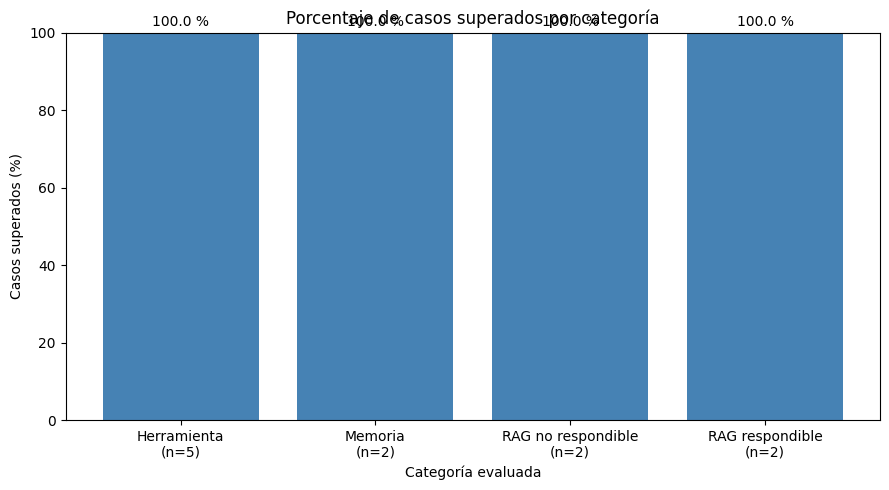

In [36]:
import matplotlib.pyplot as plt


labels = [
    (
        f"{row.category}\n"
        f"(n={row.total_cases})"
    )
    for row in evaluation_summary.itertuples()
]

values = evaluation_summary[
    "success_rate_percent"
]


fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    labels,
    values,
    color="steelblue",
)

ax.set_title(
    "Porcentaje de casos superados por categoría"
)
ax.set_xlabel("Categoría evaluada")
ax.set_ylabel("Casos superados (%)")
ax.set_ylim(0, 100)

ax.bar_label(
    bars,
    fmt="%.1f %%",
    padding=3,
)

plt.tight_layout()
plt.show()